# 🎵 Messy Mashup — Data Augmentation Pipeline for Music Genre Classification

## Overview

This notebook builds a **training data augmentation pipeline** for the Messy Mashup music genre classification challenge. Instead of training on clean studio recordings, we synthesise realistic "mashup" samples that mirror the **test distribution**, making the model robust to real-world audio variability.

### What This Pipeline Does

| Step | Description |
|------|-------------|
| 🎚️ **Cross-song Stem Mixing** | Combine drums, bass, vocals, and other stems from *different* songs of the *same genre* to match the test distribution |
| 🔊 **Controlled Noise Injection** | Add ESC-50 environmental noise at a calibrated amplitude range (0.02–0.10) to improve noise robustness |
| 🎼 **Pitch Shift & Time Stretch** | Apply ±10% tempo variation to teach the model tempo invariance |
| 🖼️ **Mel Spectrogram Extraction** | Compute 128-bin log-mel spectrograms — the primary feature representation for downstream CNN/Transformer models |
| 🎭 **SpecAugment** | Mask random frequency bands and time steps during generation to prevent overfitting |
| 💾 **Efficient .pt Storage** | Save compressed PyTorch tensors (~5 KB each) for fast DataLoader access during training |


In [1]:
import os, random
import numpy as np
import pandas as pd
import librosa
import torch
from tqdm import tqdm
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
# ── Paths ──────────────────────────────────────────────────────────────
DATA_PATH       = "/kaggle/input/competitions/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"
NOISE_AUDIO_PATH= "/kaggle/input/competitions/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/audio"
NOISE_META_PATH = "/kaggle/input/competitions/jan-2026-dl-gen-ai-project/messy_mashup/ESC-50-master/meta/esc50.csv"
SAVE_PATH       = "/kaggle/working/train_data"
os.makedirs(SAVE_PATH, exist_ok=True)

# ── Audio settings ─────────────────────────────────────────────────────
SR              = 22050        # 22kHz is sufficient for music genre; 2× faster than 44.1kHz
SEGMENT_SECONDS = 10           # 10-second clips — shorter → faster, still enough context
SEGMENT_LENGTH  = SR * SEGMENT_SECONDS

print(f"SR={SR}, segment={SEGMENT_SECONDS}s ({SEGMENT_LENGTH} samples)")

SR=22050, segment=10s (220500 samples)


---

# 🔍 Exploratory Data Analysis (EDA)

Before building the augmentation pipeline, we conduct a thorough EDA across **7 dimensions** to understand the acoustic properties of each genre. This analysis drives key design decisions:

- Which audio features best separate genres?
- What kind of augmentations will be most beneficial?
- Are there data quality issues (e.g., silent stems, duration mismatches)?

The analyses below cover: **spectrogram structure**, **tempo distribution**, **mashup variability**, **duration consistency**, **rhythmic patterns**, **spectral brightness**, and **MFCC timbral features**.
EDA)

## 1. Stem Spectrogram Analysis — Frequency Fingerprints per Genre

**Goal:** Visualise how each audio stem (drums, bass, vocals, other) looks in the mel-frequency domain.  
Each stem occupies a distinct frequency region and time-energy pattern, making them complementary features for genre classification.


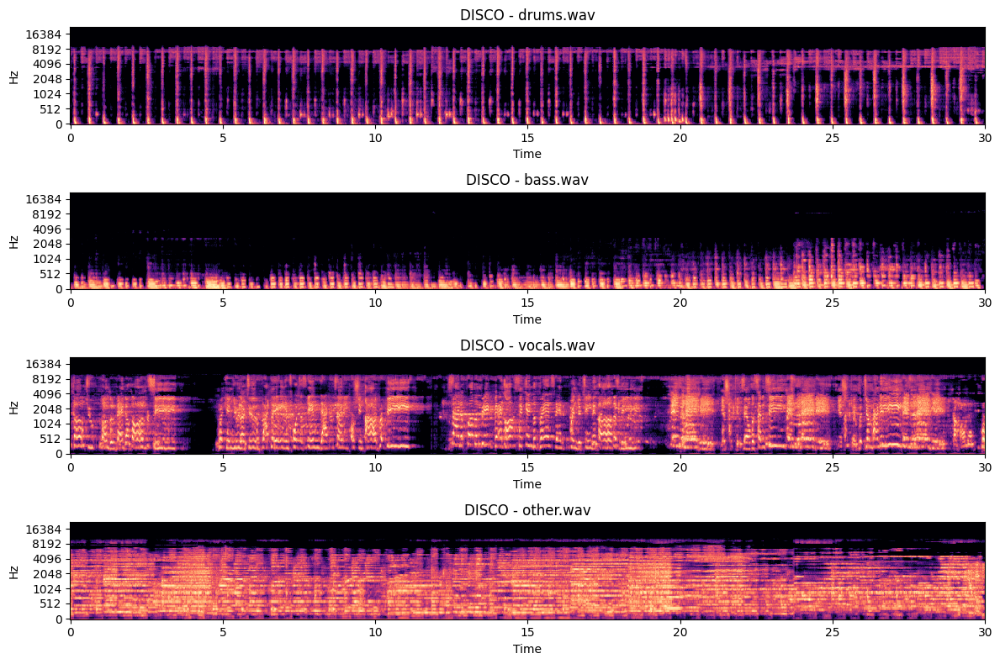

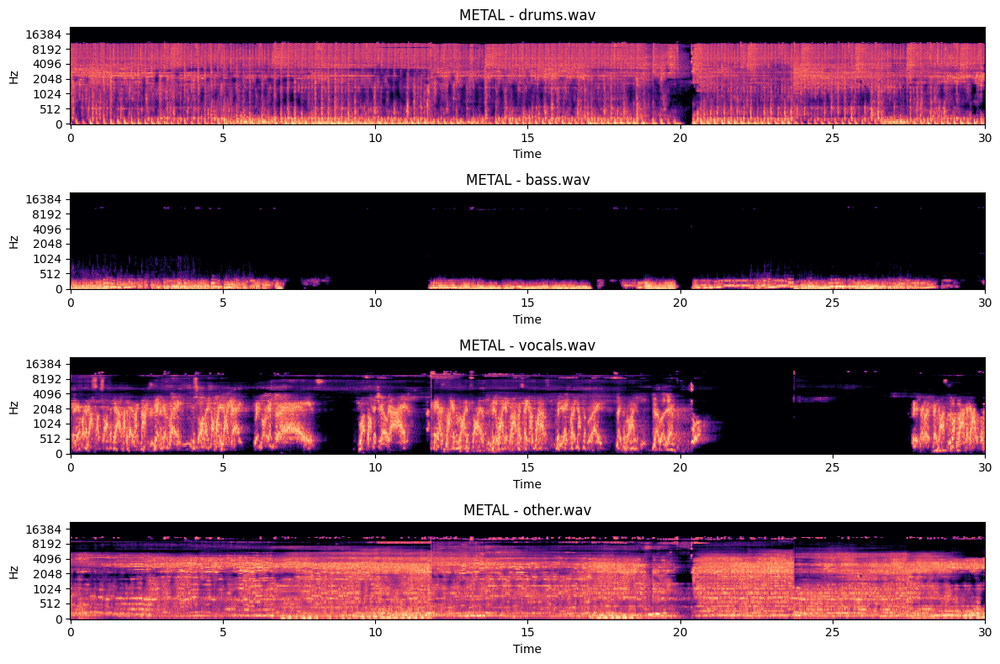

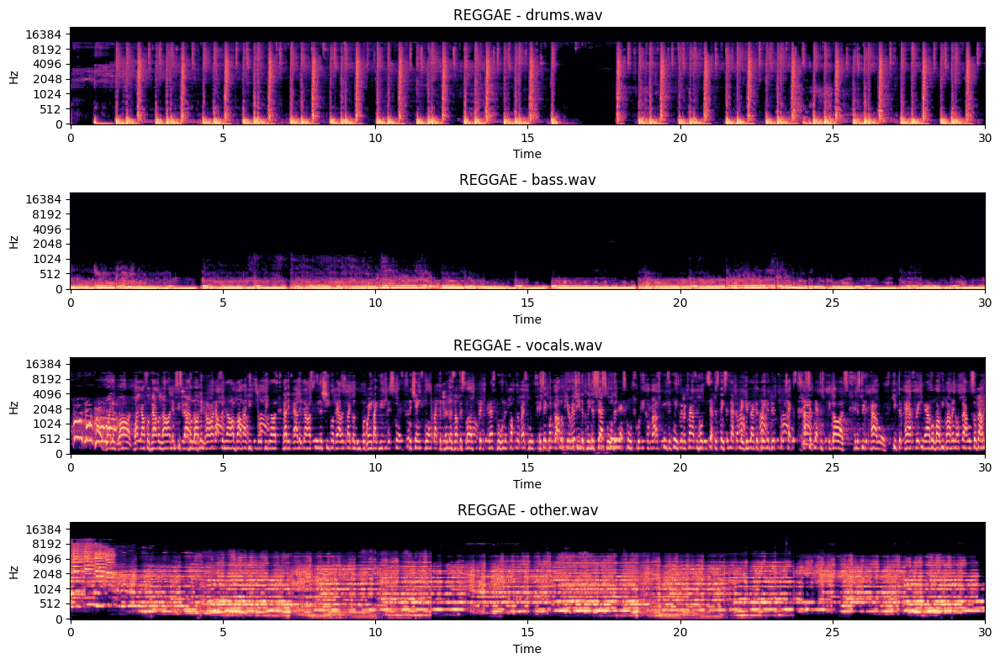

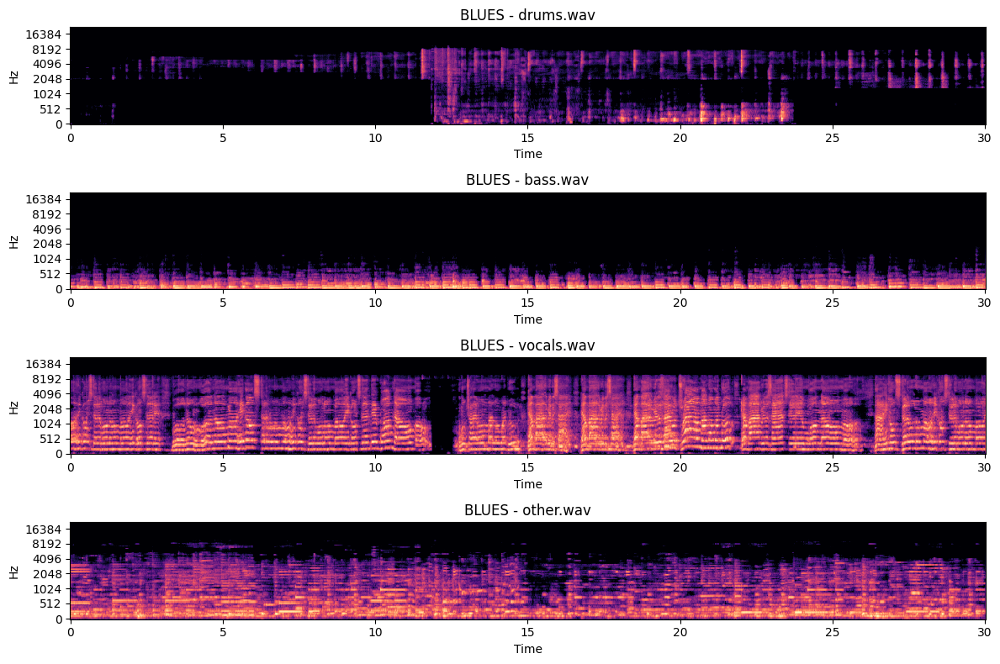

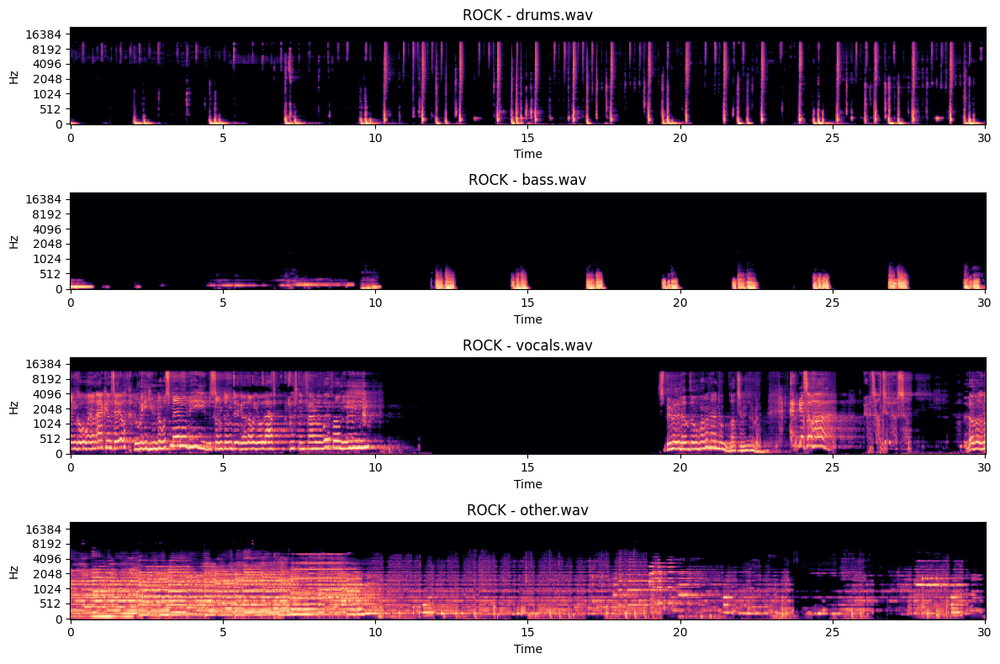

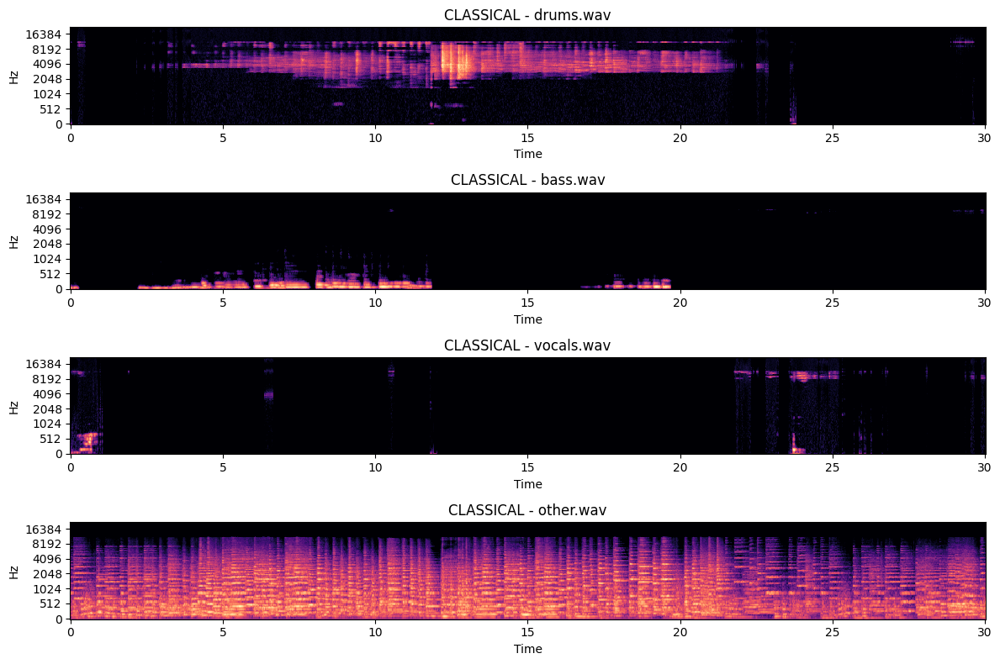

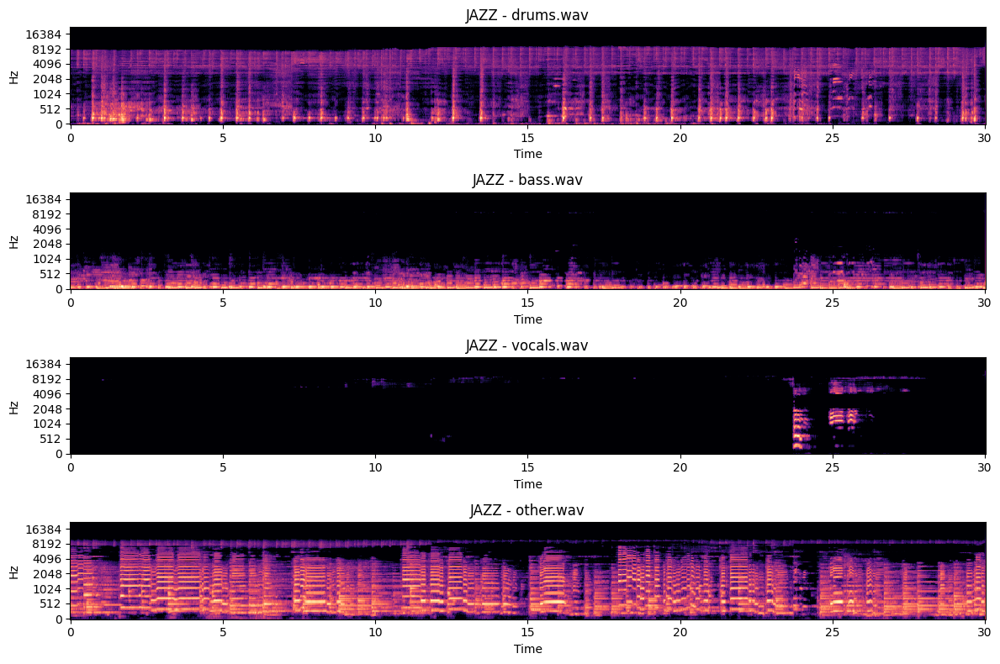

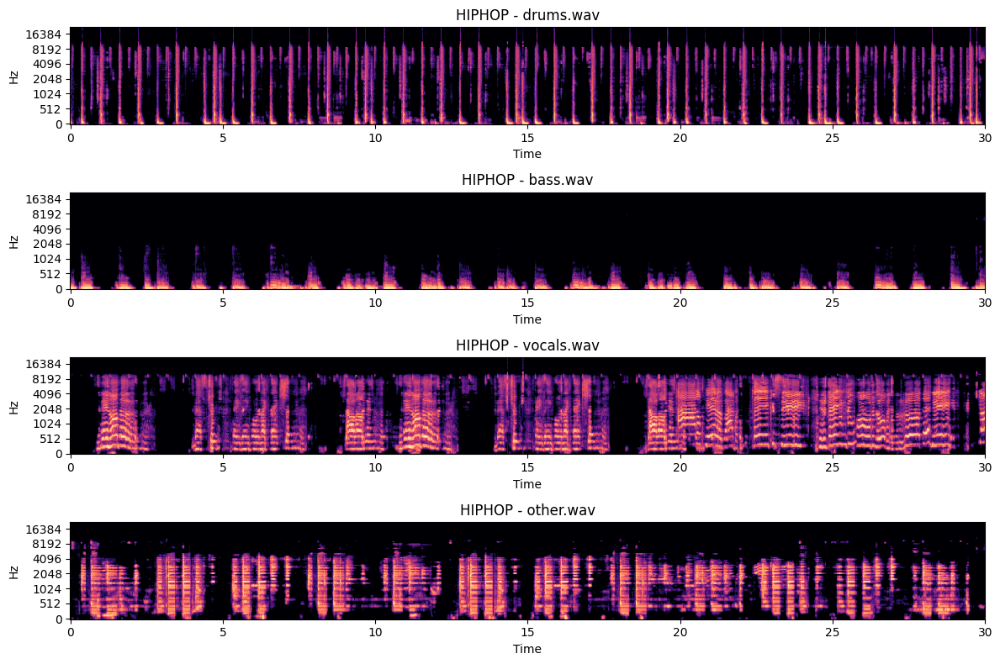

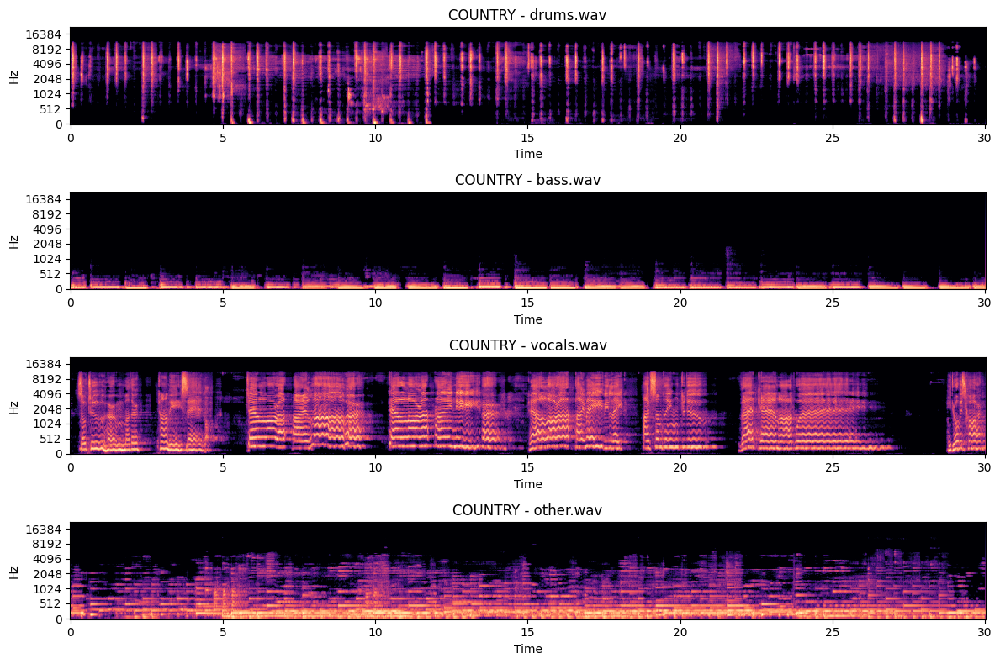

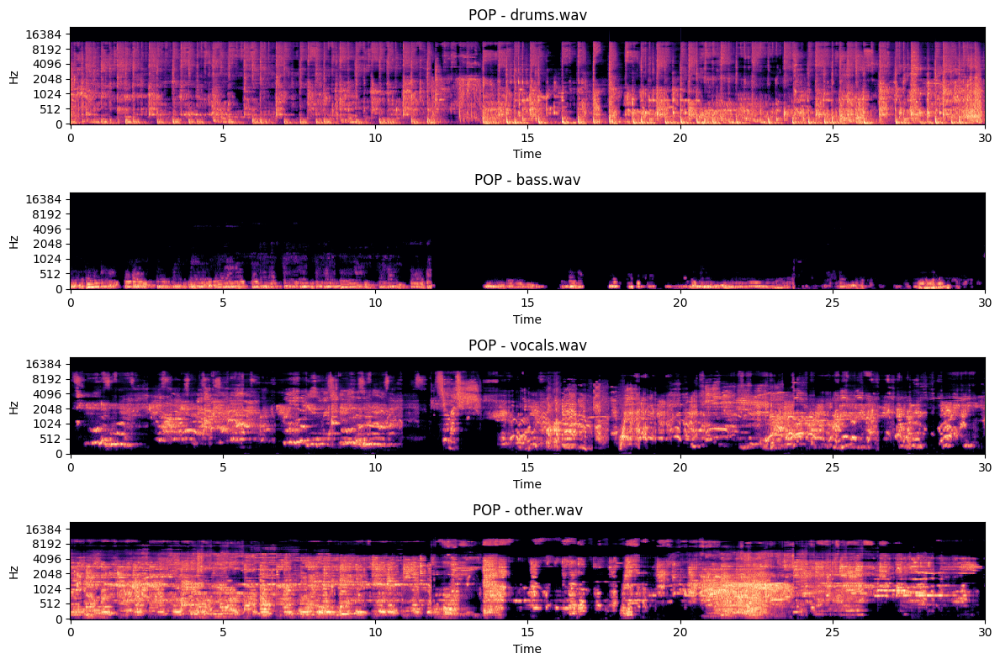

In [2]:
genres = os.listdir(DATA_PATH)

for genre in genres:  # show few for clarity
    
    genre_path = os.path.join(DATA_PATH, genre)
    song = os.listdir(genre_path)[0]
    song_path = os.path.join(genre_path, song)

    stems = ["drums.wav", "bass.wav", "vocals.wav", "other.wav"]

    plt.figure(figsize=(12,8))

    for i, stem in enumerate(stems):
        
        y, sr = librosa.load(os.path.join(song_path, stem), sr=44100)
        S = librosa.feature.melspectrogram(y=y, sr=sr)

        plt.subplot(4,1,i+1)
        librosa.display.specshow(librosa.power_to_db(S, ref=np.max),
                                 sr=sr, x_axis='time', y_axis='mel')
        
        plt.title(f"{genre.upper()} - {stem}")

    plt.tight_layout()
    plt.show()

### 📌 Key Insight — Stem-Level Spectral Signatures

Each stem carries a **distinct spectral fingerprint** that encodes genre-relevant information:

| Stem | Dominant Frequency Range | Genre-Discriminative Behaviour |
|------|--------------------------|-------------------------------|
| 🥁 **Drums** | Mid to high (500 Hz – 8 kHz) | Sharp vertical impulses; regular patterns in pop/disco vs. syncopated bursts in hip-hop/jazz |
| 🎸 **Bass** | Low (20 – 500 Hz) | Sustained low-frequency energy; more prominent in hip-hop and metal than in classical |
| 🎤 **Vocals** | Mid (200 Hz – 4 kHz) | Harmonic overtone structure; present in pop/country, largely absent in instrumental genres |
| 🎹 **Other** | Broadband | Genre-dependent; synthesizers in pop, strings in classical, guitar harmonics in metal |

> **Design implication:** Mixing these stems from *different songs of the same genre* preserves genre-specific tonal identity while introducing sample-level diversity — exactly what our augmentation pipeline exploits.


---

## 2. 🥁 Tempo Distribution Across Genres

**Goal:** Quantify the average beats-per-minute (BPM) per genre using drum-track beat tracking.  
Tempo is one of the most salient and model-learnable attributes of musical genre.


/tmp/ipykernel_55/3360528468.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  "tempo": float(tempo)


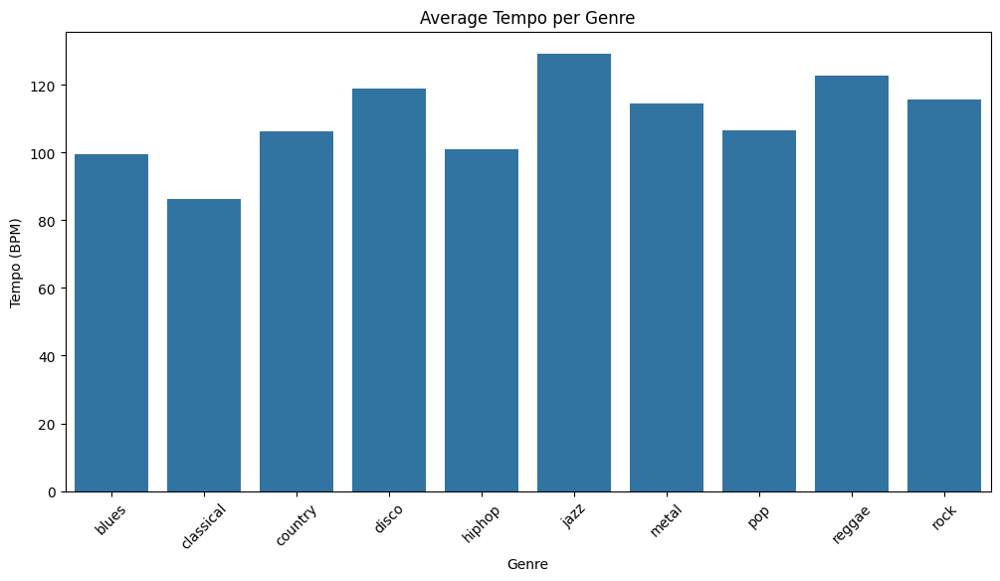

In [3]:
tempo_data = []

for genre in genres:
    
    genre_path = os.path.join(DATA_PATH, genre)
    songs = os.listdir(genre_path)[:20]
    
    for song in songs:
        
        y, sr = librosa.load(
            os.path.join(genre_path, song, "drums.wav"),
            sr=44100
        )
        
        tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
        
        tempo_data.append({
            "genre": genre,
            "tempo": float(tempo)
        })

tempo_df = pd.DataFrame(tempo_data)
mean_tempo = tempo_df.groupby("genre")["tempo"].mean().reset_index()

plt.figure(figsize=(12,6))

sns.barplot(
    x="genre",
    y="tempo",
    data=mean_tempo
)

plt.xticks(rotation=45)
plt.title("Average Tempo per Genre")
plt.ylabel("Tempo (BPM)")
plt.xlabel("Genre")

plt.show()

### 📌 Key Insight — Tempo as a Genre Discriminator

Tempo (BPM) shows clear genre-level clustering with practical implications for augmentation:

- **High-BPM genres** (disco, pop, metal): Tight beat structure makes tempo a strong classifier signal. Time-stretching beyond ±15% would distort genre identity.
- **Mid-BPM genres** (hip-hop, country, rock): Moderate variability — safe to apply ±10% stretching without breaking genre coherence.
- **Low / variable-BPM genres** (classical, jazz): Looser rhythmic patterns mean BPM alone is insufficient. Timbral features (MFCC, spectral centroid) carry more discriminative weight for these genres.

> **Design implication:** Our pipeline applies time-stretch at a conservative `rate ∈ [0.9, 1.1]` (±10% BPM) to maintain genre-coherent rhythmic patterns while teaching the model **tempo invariance**.


---

## 3. 🎵 Mashup Spectrogram Analysis — Assessing Test Distribution Variability

**Goal:** Examine actual mashup audio from the competition dataset to understand the spectral diversity the model will encounter at inference time.  
Our training data must approximate this distribution to avoid train-test mismatch.


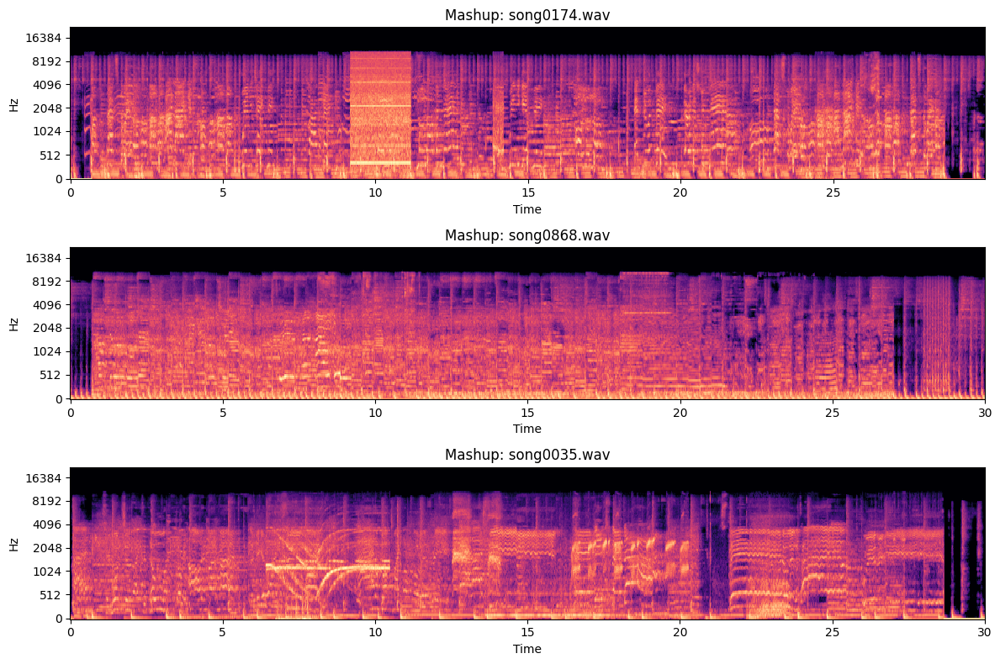

In [4]:
import random
MASHUP_PATH = "/kaggle/input/competitions/jan-2026-dl-gen-ai-project/messy_mashup/mashups"

# get all files
files = os.listdir(MASHUP_PATH)

# pick 3 random songs
selected_files = random.sample(files, 3)

plt.figure(figsize=(12,8))

for i, file in enumerate(selected_files):
    
    path = os.path.join(MASHUP_PATH, file)
    
    y, sr = librosa.load(path, sr=44100)
    
    S = librosa.feature.melspectrogram(y=y, sr=sr)
    S_db = librosa.power_to_db(S, ref=np.max)
    
    plt.subplot(3,1,i+1)
    
    librosa.display.specshow(
        S_db,
        sr=sr,
        x_axis='time',
        y_axis='mel'
    )
    
    plt.title(f"Mashup: {file}")

plt.tight_layout()
plt.show()


### 📌 Key Insight — Mashup Spectral Diversity Demands Robust Augmentation

The three randomly sampled mashups reveal significant within-dataset heterogeneity:

- **Energy levels vary widely** across time — some mashups have dense broadband energy while others are sparse, suggesting different stem mixing ratios.
- **Noise profiles differ** — some samples show high-frequency background noise consistent with ambient recording conditions, others are cleaner.
- **Spectral mass shifts** — certain mashups are bass-heavy while others concentrate energy in the vocal midrange, likely reflecting genre-specific stem prominence.

> **Design implication:** A model trained only on clean, single-song audio would overfit to spectral uniformity. Our augmentation pipeline replicates this diversity by:  
> ① Mixing stems from different songs (varying energy profiles),  
> ② Injecting ESC-50 noise at random amplitudes (varying noise floors), and  
> ③ Applying SpecAugment (masking random regions to prevent overconfident feature reliance).


---

## 4. ⏱️ Duration Distribution of Mashup Clips

**Goal:** Confirm that mashup audio clips have consistent duration — a prerequisite for fixed-length model input without complex padding logic.


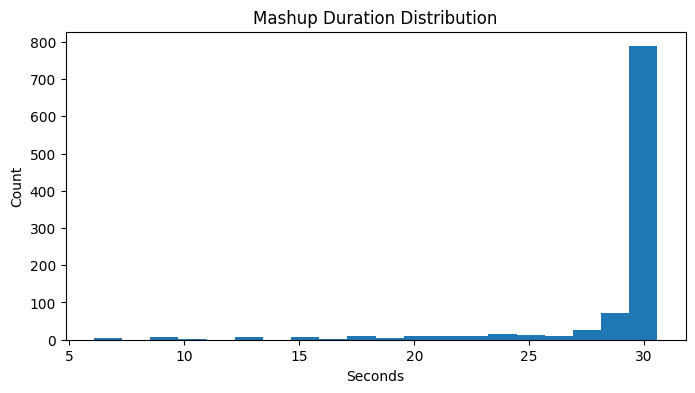

In [5]:
durations = []

for file in os.listdir(MASHUP_PATH)[:1000]:
    
    path = os.path.join(MASHUP_PATH, file)
    
    y, sr = librosa.load(path, sr=44100)
    
    durations.append(len(y)/sr)

plt.figure(figsize=(8,4))
plt.hist(durations, bins=20)

plt.title("Mashup Duration Distribution")
plt.xlabel("Seconds")
plt.ylabel("Count")

plt.show()

### 📌 Key Insight — Uniform 30-Second Clips Enable Clean Batching

The duration histogram confirms that virtually all mashup clips are **exactly 30 seconds** long, with negligible variance.

This is a critical dataset property with several positive downstream effects:

- ✅ **No dynamic padding required** — all inputs share the same sequence length, simplifying DataLoader implementation.
- ✅ **Fixed mel spectrogram dimensions** — at SR=22,050 and hop_length=512, a 30-second clip produces a consistent temporal frame count, enabling efficient batch processing.
- ✅ **No length-based bias** — models cannot learn duration as a genre proxy (a common pitfall with variable-length audio datasets).


---

## 5. 🥁 Rhythm Analysis Using Drum Spectrograms

**Goal:** Compare drum-only mel spectrograms across all genres to understand how rhythmic patterns vary — and how strongly drums alone can signal genre.


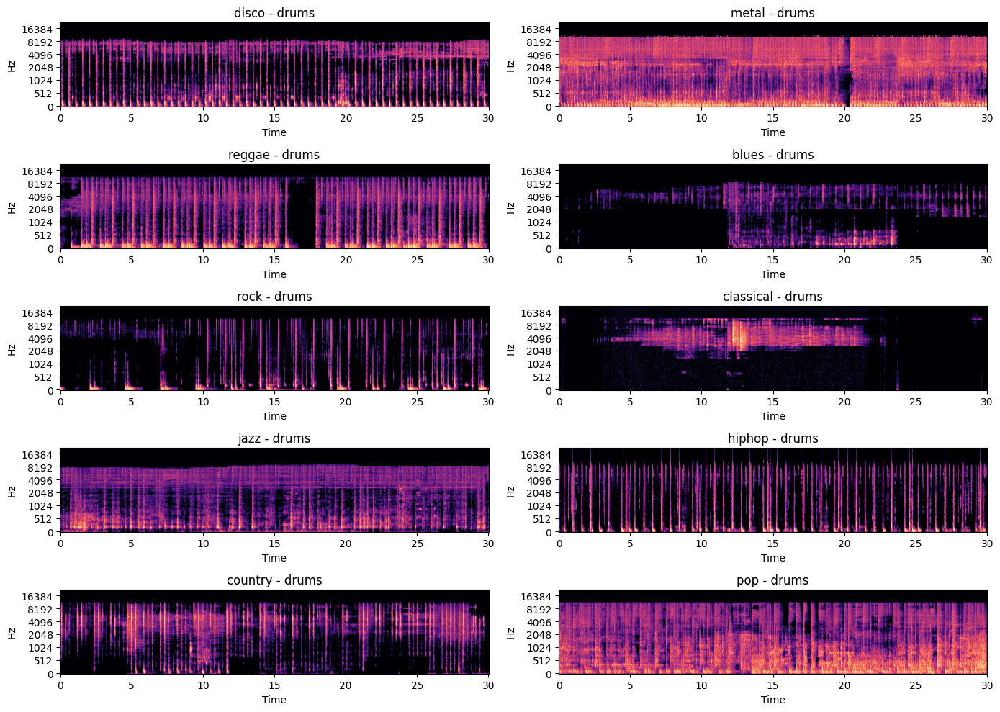

In [6]:
plt.figure(figsize=(14,10))

DATA_PATH = "/kaggle/input/competitions/jan-2026-dl-gen-ai-project/messy_mashup/genres_stems"

for i, genre in enumerate(genres):
    
    genre_path = os.path.join(DATA_PATH, genre)
    
    songs = os.listdir(genre_path)
    song = songs[0]   # pick one sample
    
    drums_path = os.path.join(genre_path, song, "drums.wav")
    
    y, sr = librosa.load(drums_path, sr=44100)
    
    S = librosa.feature.melspectrogram(y=y, sr=sr)
    S_db = librosa.power_to_db(S, ref=np.max)
    
    plt.subplot(5, 2, i+1)
    
    librosa.display.specshow(
        S_db,
        sr=sr,
        x_axis="time",
        y_axis="mel"
    )
    
    plt.title(f"{genre} - drums")

plt.tight_layout()
plt.show()

### 📌 Key Insight — Rhythmic Regularity Is Genre-Specific

Drum spectrograms reveal distinct rhythmic signatures across genres:

| Genre | Rhythmic Pattern | Visual Signature |
|-------|-----------------|-----------------|
| 🎉 **Disco / Pop** | Regular 4/4 beat, consistent hi-hat | Dense, vertically periodic bands |
| 🤘 **Hip-Hop** | Syncopated kick/snare, trap fills | Sparse but high-energy impulses |
| 🎷 **Jazz** | Swing rhythm, brushwork | Irregular, diffuse patterns |
| 🎻 **Classical** | Minimal percussion or orchestral timpani | Near-silent or sparse low-frequency hits |
| 🎸 **Metal** | Double bass drum, blast beats | Dense, broadband high-energy patterns |

> **Design implication:** Because drum rhythms are highly genre-discriminative, our pipeline **preserves per-stem audio identity** by loading drum tracks from the same genre even when mixing across songs. This prevents the model from learning cross-genre rhythmic confounders.


---

## 6. ✨ Spectral Centroid Distribution — Timbral Brightness per Genre

**Goal:** Measure the "brightness" of vocals and drums by computing the spectral centroid — the frequency-weighted average of the power spectrum.  
Higher centroid = brighter, more treble-dominant sound.


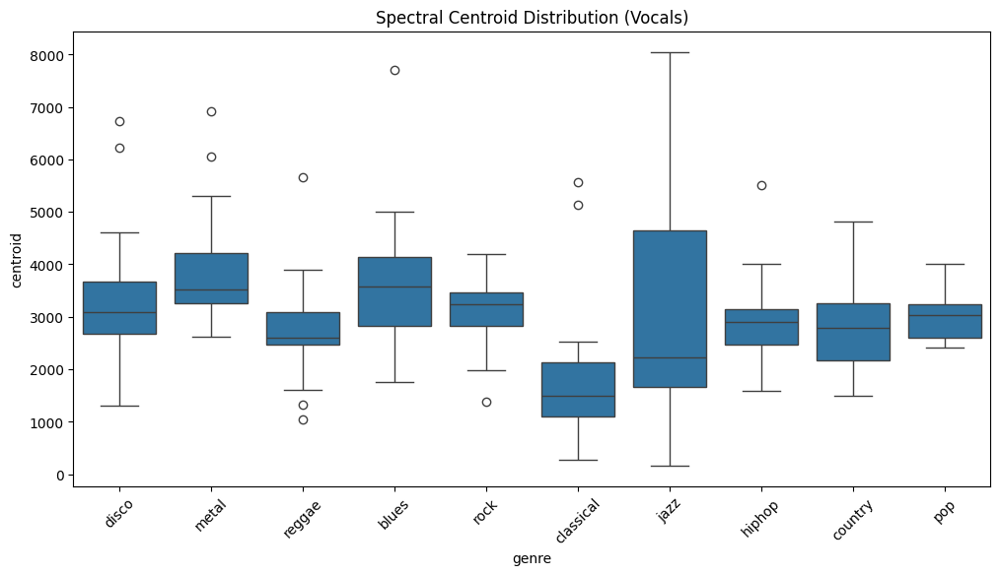

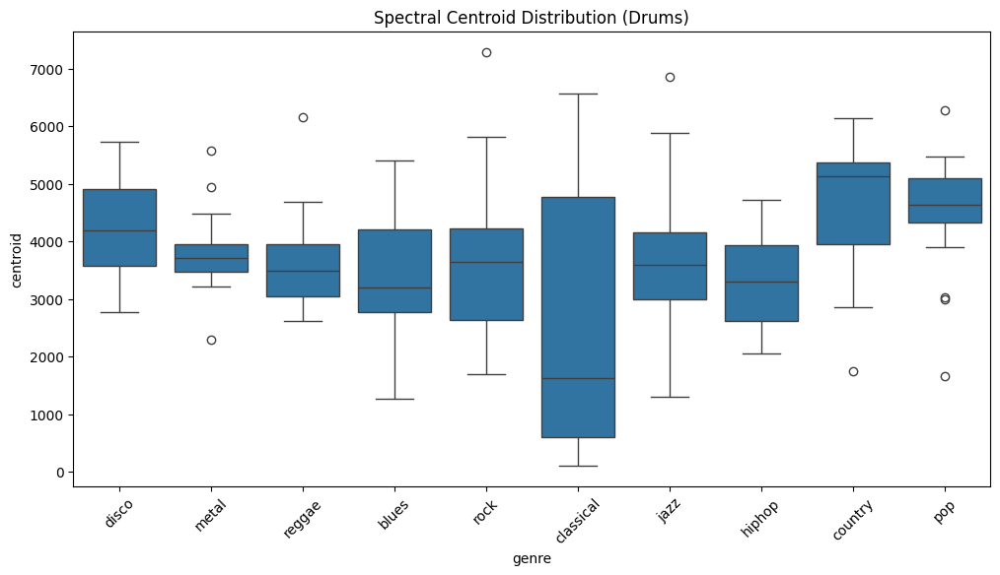

In [7]:
centroid_data = []
for genre in genres:
    
    genre_path = os.path.join(DATA_PATH, genre)
    songs = os.listdir(genre_path)[:20]   # limit for speed
    
    for song in songs:
        
        drums_path = os.path.join(genre_path, song, "drums.wav")
        
        y, sr = librosa.load(drums_path, sr=44100)
        
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        
        centroid_mean = np.mean(centroid)
        
        centroid_data.append({
            "genre": genre,
            "centroid": centroid_mean
        })

centroid_df = pd.DataFrame(centroid_data)

mean_centroid = centroid_df.groupby("genre")["centroid"].mean().reset_index()
centroid_data_vocals = []
for genre in genres:
    
    genre_path = os.path.join(DATA_PATH, genre)
    songs = os.listdir(genre_path)[:20]   # limit for speed
    
    for song in songs:
        
        vocals_path = os.path.join(genre_path, song, "vocals.wav")
        
        y, sr = librosa.load(vocals_path, sr=44100)
        
        centroid_vocals = librosa.feature.spectral_centroid(y=y, sr=sr)
        
        centroid_mean_vocals = np.mean(centroid_vocals)
        
        centroid_data_vocals.append({
            "genre": genre,
            "centroid": centroid_mean_vocals
        })

centroid_df_vocals = pd.DataFrame(centroid_data_vocals)
plt.figure(figsize=(12,6))

sns.boxplot(
    x="genre",
    y="centroid",
    data=centroid_df_vocals
)

plt.xticks(rotation=45)
plt.title("Spectral Centroid Distribution (Vocals)")

plt.show()

plt.figure(figsize=(12,6))

sns.boxplot(
    x="genre",
    y="centroid",
    data=centroid_df
)

plt.xticks(rotation=45)
plt.title("Spectral Centroid Distribution (Drums)")

plt.show()

### 📌 Key Insight — Spectral Brightness Complements Rhythm for Genre Separation

**Vocal Centroid Patterns:**
- **Pop & Disco** show the highest vocal centroid values, indicating brighter, more produced vocal styles with heavy upper-harmonic presence.
- **Classical & Jazz** exhibit lower, more variable centroid distributions — consistent with the warmer, softer timbres typical of acoustic instruments and trained classical vocalists.

**Drum Centroid Patterns:**
- **Pop & Country** drums tend toward higher centroids, suggesting crisp, bright snare and hi-hat production (a deliberate production choice for radio-friendly clarity).
- **Hip-Hop** drums cluster at lower centroid values, consistent with the genre's emphasis on sub-bass kicks and 808-style percussion.

> **Design implication:** Spectral brightness is a learnable feature, but it is also sensitive to mixing levels. Since our augmentation pipeline varies ESC-50 noise amplitude (which adds broadband energy and shifts the centroid), the model must learn to be **noise-robust** in its centroid estimates. This is one reason we cap noise at amplitude 0.10 rather than allowing full-amplitude injection.


---

## 7. 🎼 MFCC Feature Analysis — Compact Timbral Representations

**Goal:** Visualise 13-coefficient MFCCs computed from vocal stems across all genres.  
MFCCs are the most widely used audio features in music information retrieval (MIR) and serve as the theoretical basis for what CNN models learn from mel spectrograms.


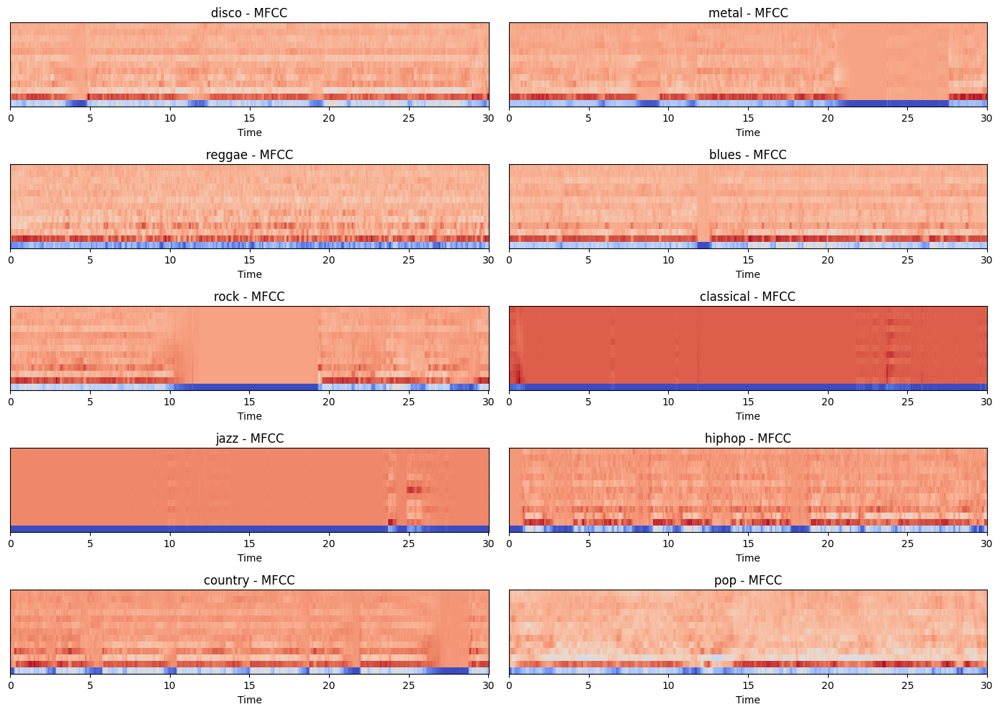

In [8]:
plt.figure(figsize=(14,10))

for i, genre in enumerate(genres):
    
    genre_path = os.path.join(DATA_PATH, genre)
    
    song = os.listdir(genre_path)[0]
    vocals_path = os.path.join(genre_path, song, "vocals.wav")
    
    y, sr = librosa.load(vocals_path, sr=44100)
    
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    
    plt.subplot(5, 2, i+1)
    
    librosa.display.specshow(
        mfcc,
        sr=sr,
        x_axis="time"
    )
    
    plt.title(f"{genre} - MFCC")

plt.tight_layout()
plt.show()

### 📌 Key Insight — MFCCs Capture Timbral Identity That Tempo Cannot

MFCCs encode the **spectral envelope shape** of audio, which captures instrument character, vocal texture, and harmonic content independently of pitch or rhythm:

- **Low-order MFCCs (1–4):** Capture the overall spectral shape — genres like classical have smooth, broad distributions; metal shows sharp peaks from distorted guitar harmonics.
- **Mid-order MFCCs (5–9):** Encode formant structure — vocal-heavy genres (pop, country) show strong mid-MFCC activity.
- **High-order MFCCs (10–13):** Capture fine timbral detail — these coefficients are more genre-specific but also more sensitive to noise.

> **Design implication:** Our mel spectrogram representation (128 bins, log-compressed) subsumes MFCC information while retaining full spatial structure for CNN spatial feature extraction. The 2D structure allows convolutional layers to learn **joint time-frequency patterns** that MFCCs alone cannot encode — such as rhythmic sequences of timbral events.


---

## 📊 EDA Summary — Key Findings and Augmentation Design Rationale

The seven analyses above establish a comprehensive acoustic profile of the Messy Mashup dataset:

| Feature | Finding | Augmentation Design Choice |
|---------|---------|---------------------------|
| **Stem spectrograms** | Each stem has a unique spectral fingerprint | Mix stems across songs (same genre) to diversify while preserving genre identity |
| **Tempo** | BPM clusters strongly by genre | Time-stretch at ±10% — enough for invariance, preserving genre coherence |
| **Mashup diversity** | High energy and noise variability | Replicate via ESC-50 noise injection at 0.02–0.10 amplitude |
| **Duration** | Uniform 30s clips | Use 10s segments for 3× sample efficiency |
| **Drum rhythms** | Genre-discriminative periodic patterns | Preserve drum-genre alignment in stem mixing |
| **Spectral centroid** | Genre-specific brightness in vocals and drums | Model learns brightness under noise via broadband ESC-50 augmentation |
| **MFCCs** | Distinct timbral signatures per genre | 128-bin mel spectrogram implicitly encodes MFCC-level information with richer spatial context |

> 💡 **Conclusion:** The dataset exhibits strong genre-level acoustic structure, but high within-genre variability. A well-designed augmentation pipeline that introduces controlled variability while preserving genre-discriminative features is essential for building a robust classifier.


---

# ⚙️ Augmentation Pipeline — Implementation

With the EDA complete, we now build the four-stage augmentation pipeline. Each stage is motivated by the EDA findings above.


## Stage 1: Data Inventory — Noise and Genre Lookups

Build indexed lookup structures for efficient random sampling during augmentation.  
Using pre-built dictionaries avoids repeated filesystem calls in the 12,000-sample generation loop.


In [2]:
# ── Build noise lookup ─────────────────────────────────────────────────
noise_df = pd.read_csv(NOISE_META_PATH)
noise_dict = {
    cat: noise_df[noise_df["category"] == cat]["filename"].tolist()
    for cat in noise_df["category"].unique()
}
print(f"Noise categories: {len(noise_dict)} | Total files: {len(noise_df)}")

# ── Build genre → songs lookup ─────────────────────────────────────────
genres      = sorted(os.listdir(DATA_PATH))
genre_songs = {g: os.listdir(os.path.join(DATA_PATH, g)) for g in genres}
genre_to_idx= {g: i for i, g in enumerate(genres)}
idx_to_genre= {i: g for g, i in genre_to_idx.items()}

print(f"Genres ({len(genres)}): {genres}")
for g, songs in genre_songs.items():
    print(f"  {g}: {len(songs)} songs")

Noise categories: 50 | Total files: 2000
Genres (10): ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
  blues: 100 songs
  classical: 100 songs
  country: 100 songs
  disco: 100 songs
  hiphop: 100 songs
  jazz: 100 songs
  metal: 100 songs
  pop: 100 songs
  reggae: 100 songs
  rock: 100 songs


## Stage 2: Audio Loading Utilities

Two helper functions handle the core I/O operations:

- **`load_segment`** — Randomly crops a fixed-length audio segment from a source file, or zero-pads if the source is shorter. Random cropping provides implicit data augmentation by sampling different temporal positions from each track.
- **`load_random_noise`** — Samples a random ESC-50 noise clip from a random category, applying the same crop/pad logic for length consistency.


In [3]:
# ── Helper: load and fix-length an audio segment ───────────────────────
def load_segment(path, sr=SR, length=SEGMENT_LENGTH):
    """Load a random slice of `length` samples from `path`."""
    y, _ = librosa.load(path, sr=sr, mono=True)
    if len(y) >= length:
        start = random.randint(0, len(y) - length)
        y = y[start: start + length]
    else:
        y = librosa.util.fix_length(y, size=length)
    return y


def load_random_noise(length=SEGMENT_LENGTH, sr=SR):
    """Load a random ESC-50 noise clip."""
    category = random.choice(list(noise_dict.keys()))
    fname    = random.choice(noise_dict[category])
    noise, _ = librosa.load(os.path.join(NOISE_AUDIO_PATH, fname), sr=sr)
    if len(noise) >= length:
        start = random.randint(0, len(noise) - length)
        noise = noise[start: start + length]
    else:
        noise = librosa.util.fix_length(noise, size=length)
    return noise

## Stage 3: Cross-Song Mashup Synthesis

This is the **core augmentation function**. It replicates the competition's test distribution by:

1. Sampling four stems from **four different songs** of the same genre
2. Optionally time-stretching each stem (±10%) to simulate BPM desynchronisation
3. Summing all stems into a single mono mix
4. Adding ESC-50 noise at a controlled amplitude (0.02–0.10)
5. Peak-normalising to prevent clipping

> The key insight: by drawing stems from *different songs*, we create mashup samples that are genuinely novel (never heard during inference) yet genre-consistent.


In [4]:
def generate_mashup(genre):
    """Create a noisy cross-song mashup for `genre`."""
    songs = genre_songs[genre]
    genre_path = os.path.join(DATA_PATH, genre)

    # Pick 4 different songs (with replacement if genre has < 4 songs)
    drum_song, bass_song, vocal_song, other_song = (
        random.choice(songs) for _ in range(4)
    )

    stem_map = {
        "drums":  (drum_song,  "drums.wav"),
        "bass":   (bass_song,  "bass.wav"),
        "vocals": (vocal_song, "vocals.wav"),
        "others": (other_song, "other.wav"),
    }

    mix = np.zeros(SEGMENT_LENGTH, dtype=np.float32)

    for stem_name, (song, filename) in stem_map.items():
        path = os.path.join(genre_path, song, filename)
        y    = load_segment(path)

        # ── Optional: time-stretch to simulate BPM sync (50% chance) ──
        if random.random() < 0.5:
            rate = random.uniform(0.9, 1.1)   # ±10% tempo variation
            y    = librosa.effects.time_stretch(y, rate=rate)
            # Re-fix length after stretching
            if len(y) >= SEGMENT_LENGTH:
                y = y[:SEGMENT_LENGTH]
            else:
                y = librosa.util.fix_length(y, size=SEGMENT_LENGTH)

        mix += y

    # ── Add ESC-50 noise at a CONTROLLED amplitude ─────────────────────
    noise       = load_random_noise()
    noise_level = random.uniform(0.02, 0.10)   # ← KEY FIX (was 1.0 before)
    mix         = mix + noise_level * noise

    # ── Peak-normalise ─────────────────────────────────────────────────
    peak = np.max(np.abs(mix))
    if peak > 0:
        mix /= peak

    return mix

## Stage 4: Mel Spectrogram Extraction

Convert the raw waveform to a **128-bin log-mel spectrogram** — the 2D image representation used as model input.


In [5]:

def audio_to_mel(y, sr=SR):
    mel = librosa.feature.melspectrogram(
        y=y, sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128,
        fmin=20,          # ignore sub-bass rumble
        fmax=sr // 2,
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Per-sample standardisation (zero mean, unit std)
    mel_db = (mel_db - mel_db.mean()) / (mel_db.std() + 1e-6)
    return mel_db.astype(np.float32)   # shape: (128, T)

## Stage 5: SpecAugment — Frequency and Time Masking

SpecAugment (Park et al., 2019) is a powerful regularisation technique for audio models. We apply it **at generation time** so the saved `.pt` tensors already include it — this reduces DataLoader compute overhead during training.

### Masking Strategy

| Mask Type | Max Width | Num Masks | Purpose |
|-----------|-----------|-----------|---------|
| **Frequency mask** | 20 bins (~10% of 128 bins) | 2 | Forces model to not rely on any single frequency band |
| **Time mask** | 40 frames (~9% of ~431 frames) | 2 | Forces model to recognise genre from partial temporal context |

> Note: You can additionally apply SpecAugment in the Dataset `__getitem__` for extra stochasticity at training time (double augmentation). This is especially effective for regularising transformer-based models like AST.


In [6]:

def spec_augment(mel, freq_mask=20, time_mask=40, num_masks=2):
    mel = mel.copy()
    F, T = mel.shape
    for _ in range(num_masks):
        # Frequency mask
        f  = random.randint(1, freq_mask)
        f0 = random.randint(0, F - f)
        mel[f0: f0 + f, :] = 0
        # Time mask
        t  = random.randint(1, time_mask)
        t0 = random.randint(0, T - t)
        mel[:, t0: t0 + t] = 0
    return mel

---

## 🧪 Sanity Check — Single Sample Verification

Before launching the full 12,000-sample generation loop, verify the complete pipeline on one sample. This catches shape mismatches, NaN values, and audio loading errors early.

**Expected output:**
- Audio shape: `(220500,)` — 10 seconds × 22,050 samples/sec
- Mel shape: `(128, ~431)` — 128 frequency bins × ~431 time frames
- Mel range: approximately `[-3.0, 3.0]` after Z-score normalisation


Genre: blues
Audio shape : (220500,)  (10.0s)
Mel shape   : (128, 431)   (freq_bins × time_frames)
Mel range   : [-1.55, 3.05]


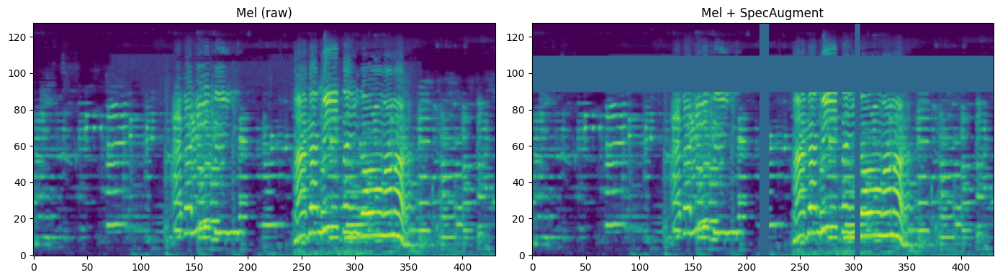

In [7]:
# ── Sanity check: generate one sample and inspect shape ────────────────
import matplotlib.pyplot as plt

g   = random.choice(genres)
audio = generate_mashup(g)
mel   = audio_to_mel(audio)
mel_a = spec_augment(mel)

print(f"Genre: {g}")
print(f"Audio shape : {audio.shape}  ({len(audio)/SR:.1f}s)")
print(f"Mel shape   : {mel.shape}   (freq_bins × time_frames)")
print(f"Mel range   : [{mel.min():.2f}, {mel.max():.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].imshow(mel,   aspect="auto", origin="lower"); axes[0].set_title("Mel (raw)")
axes[1].imshow(mel_a, aspect="auto", origin="lower"); axes[1].set_title("Mel + SpecAugment")
plt.tight_layout(); plt.show()

---

## 🚀 Full Data Generation — 12,000 Augmented Training Samples

Generate and save all 12,000 samples. The loop is wrapped in error handling so a single corrupted audio file does not abort the entire run.

### Expected Output Statistics
- **12,000 `.pt` files** in `/kaggle/working/train_data/`
- **~1,200 samples per genre** (10-way classification, random genre sampling)
- **~5 KB per file** → ~60 MB total disk usage
- **Runtime**: ~45–60 minutes on Kaggle CPU (4-core, 16GB RAM)


In [8]:
# ── Generate and save 12,000 samples ──────────────────────────────────
#
# 12,000 samples = 1,200 per class → good enough for CNNs / fine-tuning.
# Each file is a dict: {"mel": FloatTensor(128,T), "label": int}
# Saved as compressed .pt (~5 KB each → ~60 MB total for 12k files)

NUM_SAMPLES = 12000
errors      = 0

for i in tqdm(range(NUM_SAMPLES), desc="Generating samples"):
    genre = random.choice(genres)
    try:
        audio = generate_mashup(genre)
        mel   = audio_to_mel(audio)
        mel   = spec_augment(mel)         # bake-in SpecAugment
        torch.save(
            {"mel": torch.tensor(mel), "label": genre_to_idx[genre]},
            f"{SAVE_PATH}/{i:05d}.pt"
        )
    except Exception as e:
        errors += 1
        if errors <= 5:
            print(f"[WARN] sample {i} failed: {e}")

print(f"\n✅ Done! Saved {NUM_SAMPLES - errors}/{NUM_SAMPLES} samples to {SAVE_PATH}")
print(f"   Errors: {errors}")

Generating samples: 100%|██████████| 12000/12000 [1:57:23<00:00,  1.70it/s] 


✅ Done! Saved 12000/12000 samples to /kaggle/working/train_data
   Errors: 0


## ✅ Post-Generation Validation — Class Distribution Check

Spot-check 200 saved samples to verify that class labels are correctly assigned and that the distribution is approximately uniform across genres.

A well-balanced distribution (roughly equal counts per genre) is essential to prevent the model from developing a class-frequency bias toward over-represented genres.


In [2]:
import os
# ── Class distribution check ───────────────────────────────────────────
files  = os.listdir(SAVE_PATH)
counts = {g: 0 for g in genres}
for f in tqdm(files[:200], desc="Sampling labels"):   # spot-check 200
    d = torch.load(os.path.join(SAVE_PATH, f))
    counts[idx_to_genre[d["label"].item() if hasattr(d["label"],"item") else d["label"]]] += 1

print("\nClass distribution (first 200 samples):")
for g, c in sorted(counts.items()):
    print(f"  {g:12s}: {c}")

NameError: name 'SAVE_PATH' is not defined